# Lab 3. Digital filter design and analysis: FIR, IIR and adaptive LMS filters - variant 7

- FIR: `b = {1, -1, 0.5}`
- IIR: `b = {0.3, 0.4}`, `a = {1, -0.5, 0.2}`
- LMS: `mu = 0.05`, filter length `M = 4`

All three filters are applied to the same noisy sinusoid.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, freqz, tf2zpk

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})

b_fir = np.array([1, -1, 0.5])
b_iir = np.array([0.3, 0.4])
a_iir = np.array([1, -0.5, 0.2])
mu, M = 0.05, 4

fs, N = 1000, 1000
f0, sigma = 5, 0.5
t = np.arange(N)/fs
d = np.sin(2*np.pi*f0*t)
rng = np.random.default_rng(0)
x = d + sigma*rng.standard_normal(N)

def snr_db(clean, sig):
    return 10*np.log10(np.sum(clean**2)/np.sum((sig - clean)**2))

print("input SNR = %.2f dB" % snr_db(d, x))

input SNR = 3.20 dB


## FIR filter

$y[n] = \sum_{k=0}^{M} b_k x[n-k]$. The manual's loop starts at `n = M`, so the first samples stay zero. Here the sum is computed for every `n` (missing past samples are taken as 0), which is the same as `scipy.signal.lfilter(b, 1, x)`.

In [2]:
def fir_filter(x, b):
    b = np.asarray(b, dtype=float)
    y = np.zeros(len(x))
    for n in range(len(x)):
        k = min(len(b), n + 1)
        y[n] = np.dot(b[:k], x[n::-1][:k])
    return y

y_fir = fir_filter(x, b_fir)
print("max |own - lfilter| =", np.abs(y_fir - lfilter(b_fir, [1], x)).max())
print("FIR output SNR = %.2f dB" % snr_db(d, y_fir))

max |own - lfilter| = 4.440892098500626e-16
FIR output SNR = -1.13 dB


## IIR filter

$y[n] = \sum_{k=0}^{M} b_k x[n-k] - \sum_{k=1}^{N} a_k y[n-k]$ (with $a_0 = 1$).

In [3]:
def iir_filter(x, b, a):
    b, a = np.asarray(b, dtype=float), np.asarray(a, dtype=float)
    y = np.zeros(len(x))
    for n in range(len(x)):
        kb = min(len(b), n + 1)
        ka = min(len(a) - 1, n)
        y[n] = np.dot(b[:kb], x[n::-1][:kb])
        if ka > 0:
            y[n] -= np.dot(a[1:ka + 1], y[n-1::-1][:ka])
    return y / a[0]

y_iir = iir_filter(x, b_iir, a_iir)
print("max |own - lfilter| =", np.abs(y_iir - lfilter(b_iir, a_iir, x)).max())
print("IIR output SNR = %.2f dB" % snr_db(d, y_iir))

z, p, k = tf2zpk(b_iir, a_iir)
print("poles:", np.round(p, 4), " |p| =", np.round(np.abs(p), 4), "-> stable" if np.all(np.abs(p) < 1) else "-> UNSTABLE")

max |own - lfilter| = 2.220446049250313e-16
IIR output SNR = 6.71 dB
poles: [0.25+0.3708j 0.25-0.3708j]  |p| = [0.4472 0.4472] -> stable


## LMS adaptive filter

$y[n] = \mathbf{w}^T[n]\mathbf{x}[n]$, $e[n] = d[n] - y[n]$, $\mathbf{w}[n+1] = \mathbf{w}[n] + \mu\, e[n]\, \mathbf{x}[n]$, with $\mathbf{x}[n] = [x[n], x[n-1], \dots, x[n-M+1]]^T$ (current and `M-1` previous samples, as in section 4.1 of the manual). Unlike the manual's code, the current sample `x[n]` is included in the input vector.

In [4]:
def lms_filter(x, d, mu, num_taps):
    n = len(x)
    w = np.zeros(num_taps)
    y = np.zeros(n)
    e = np.zeros(n)
    W = np.zeros((n, num_taps))
    xp = np.concatenate([np.zeros(num_taps - 1), x])
    for i in range(n):
        x_vec = xp[i:i + num_taps][::-1]
        y[i] = np.dot(w, x_vec)
        e[i] = d[i] - y[i]
        w = w + mu*e[i]*x_vec
        W[i] = w
    return y, e, w, W

y_lms, e_lms, w_lms, W_lms = lms_filter(x, d, mu, M)

Rxx = np.array([[np.mean(x[i:N-M+1+i]*x[j:N-M+1+j]) for j in range(M)] for i in range(M)])
lam_max = np.linalg.eigvalsh(Rxx).max()
print("final weights:", np.round(w_lms, 4))
print("lambda_max = %.3f -> mu_max = 2/lambda_max = %.3f (mu = %.2f %s)" % (lam_max, 2/lam_max, mu, "OK" if mu < 2/lam_max else "TOO LARGE"))
print("LMS output SNR = %.2f dB (whole record), %.2f dB (after convergence, n >= 200)" % (snr_db(d, y_lms), snr_db(d[200:], y_lms[200:])))

final weights: [0.128  0.1335 0.1407 0.1696]
lambda_max = 2.382 -> mu_max = 2/lambda_max = 0.840 (mu = 0.05 OK)
LMS output SNR = 10.04 dB (whole record), 10.23 dB (after convergence, n >= 200)


## Time-domain results

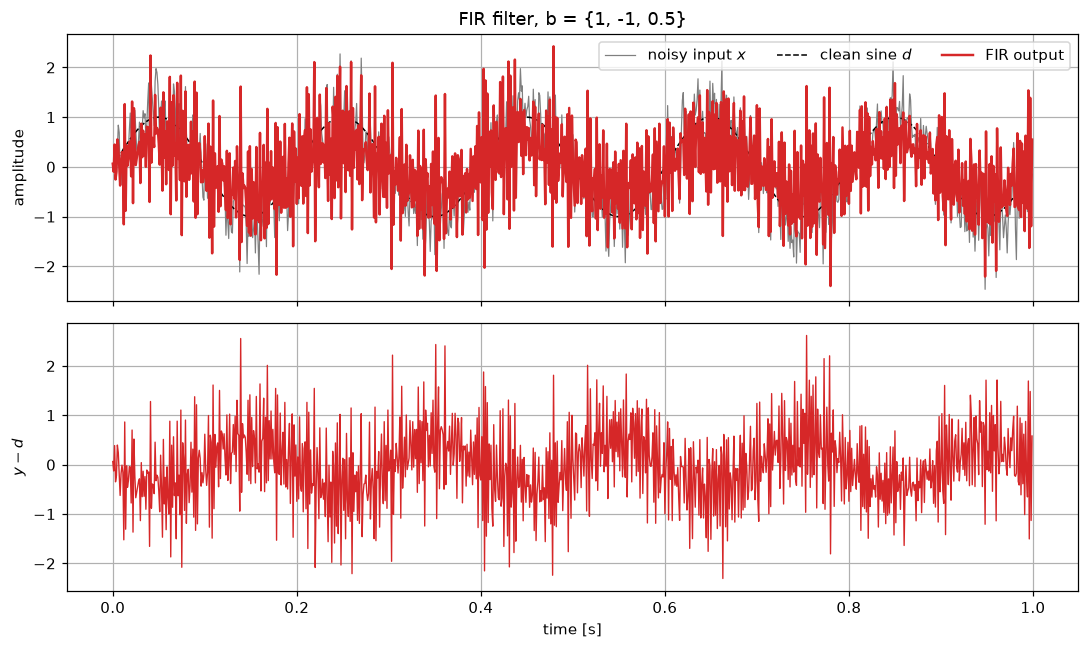

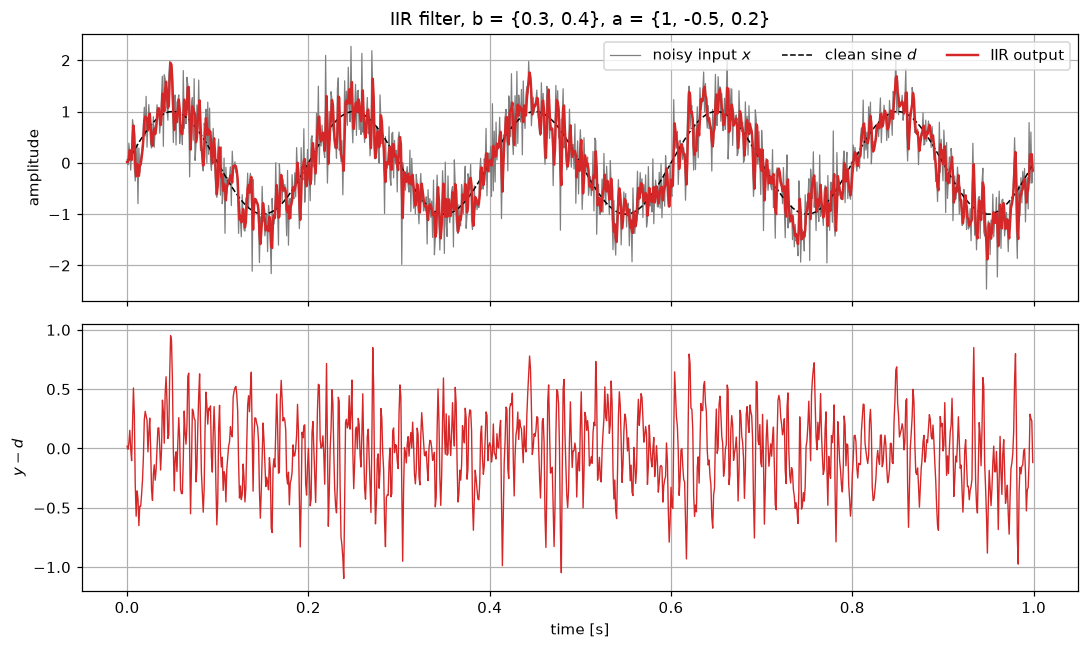

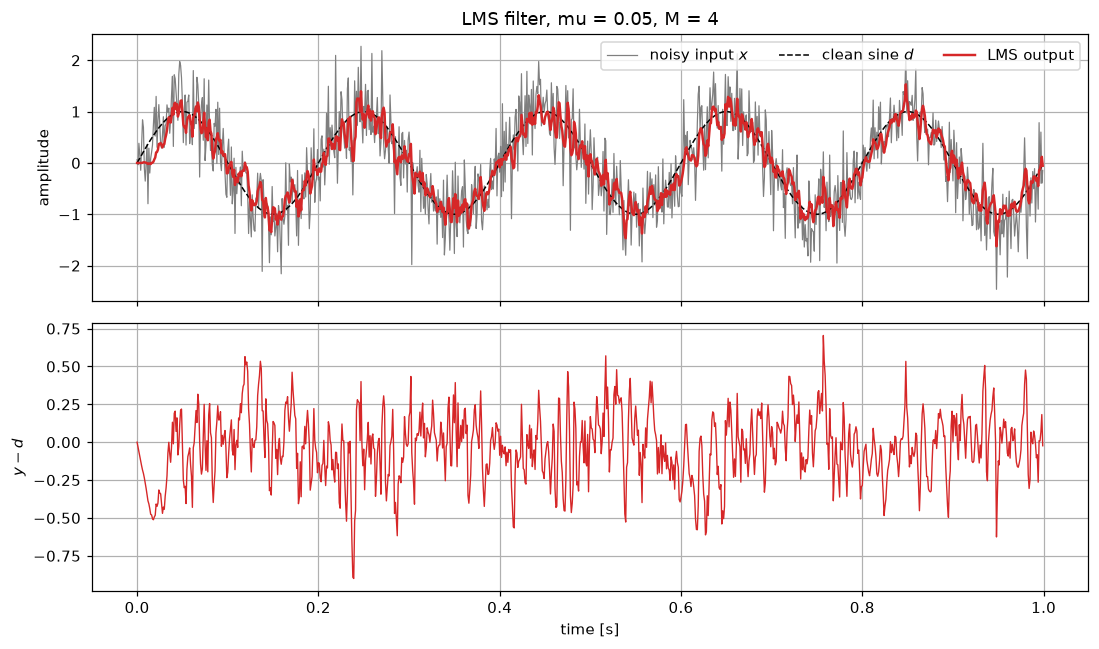

In [5]:
def plot_result(y, title, fname, label):
    fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    axs[0].plot(t, x, color="C7", lw=0.8, label="noisy input $x$")
    axs[0].plot(t, d, "k--", lw=1, label="clean sine $d$")
    axs[0].plot(t, y, "C3", lw=1.6, label=label)
    axs[0].set_ylabel("amplitude"); axs[0].legend(loc="upper right", ncol=3); axs[0].set_title(title)
    axs[1].plot(t, y - d, "C3", lw=0.9)
    axs[1].set_ylabel("$y - d$"); axs[1].set_xlabel("time [s]")
    fig.tight_layout(); fig.savefig(fname, bbox_inches="tight"); plt.show()

plot_result(y_fir, "FIR filter, b = {1, -1, 0.5}", "fig_fir.png", "FIR output")
plot_result(y_iir, "IIR filter, b = {0.3, 0.4}, a = {1, -0.5, 0.2}", "fig_iir.png", "IIR output")
plot_result(y_lms, "LMS filter, mu = 0.05, M = 4", "fig_lms.png", "LMS output")

## Frequency responses of the FIR and IIR filters

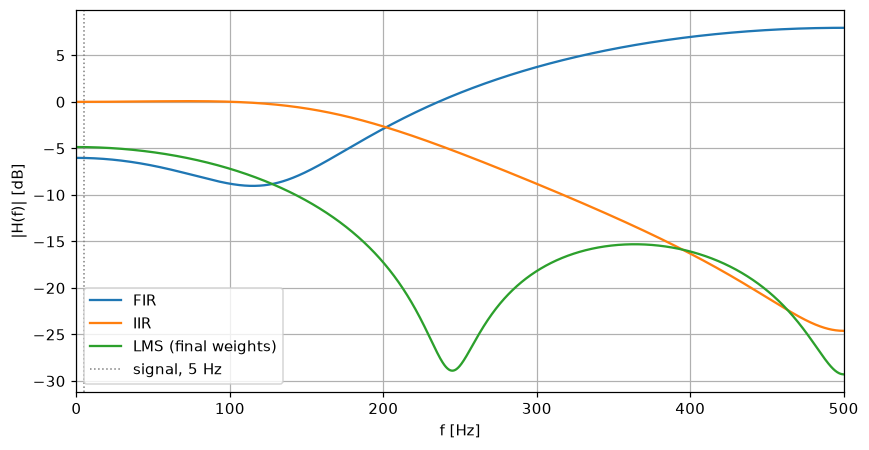

FIR: |H(5 Hz)| = 0.500, |H(f=fs/2)| = 2.500, mean |H|^2 (noise power gain) = 2.249
IIR: |H(5 Hz)| = 1.000, |H(f=fs/2)| = 0.059, mean |H|^2 (noise power gain) = 0.441
LMS: |H(5 Hz)| = 0.571, |H(f=fs/2)| = 0.034, mean |H|^2 (noise power gain) = 0.083


In [6]:
w, H_fir = freqz(b_fir, [1], worN=2048, fs=fs)
_, H_iir = freqz(b_iir, a_iir, worN=2048, fs=fs)
_, H_lms = freqz(w_lms, [1], worN=2048, fs=fs)

plt.figure(figsize=(9, 4.5))
for H, lab in [(H_fir, "FIR"), (H_iir, "IIR"), (H_lms, "LMS (final weights)")]:
    plt.plot(w, 20*np.log10(np.abs(H)), label=lab)
plt.axvline(f0, color="gray", ls=":", lw=1, label="signal, 5 Hz")
plt.xlim(0, fs/2); plt.xlabel("f [Hz]"); plt.ylabel("|H(f)| [dB]"); plt.legend()
plt.savefig("fig_freqresp.png", bbox_inches="tight"); plt.show()

for name, H in [("FIR", H_fir), ("IIR", H_iir), ("LMS", H_lms)]:
    print("%s: |H(5 Hz)| = %.3f, |H(f=fs/2)| = %.3f, mean |H|^2 (noise power gain) = %.3f" % (
        name, np.abs(H[np.argmin(np.abs(w - f0))]), np.abs(H[-1]), np.mean(np.abs(H)**2)))

## LMS convergence

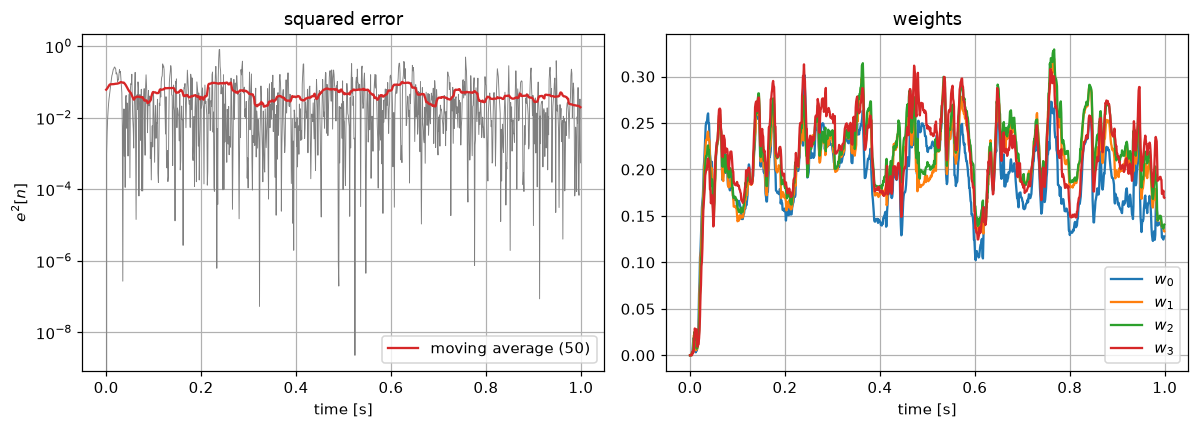

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(t, e_lms**2, lw=0.6, color="C7")
axs[0].plot(t, np.convolve(e_lms**2, np.ones(50)/50, mode="same"), "C3", label="moving average (50)")
axs[0].set_yscale("log"); axs[0].set_xlabel("time [s]"); axs[0].set_ylabel("$e^2[n]$"); axs[0].legend()
axs[0].set_title("squared error")
for j in range(M):
    axs[1].plot(t, W_lms[:, j], label=f"$w_{j}$")
axs[1].set_xlabel("time [s]"); axs[1].set_title("weights"); axs[1].legend()
fig.tight_layout(); fig.savefig("fig_lms_conv.png", bbox_inches="tight"); plt.show()

## Comparison

In [8]:
import pandas as pd
ref = slice(200, None)
rows = {
    "noisy input": x,
    "FIR": y_fir,
    "IIR": y_iir,
    "LMS": y_lms,
}
df = pd.DataFrame({
    "SNR [dB]": {n: snr_db(d, s) for n, s in rows.items()},
    "SNR, n>=200 [dB]": {n: snr_db(d[ref], s[ref]) for n, s in rows.items()},
    "MSE vs clean": {n: np.mean((s - d)**2) for n, s in rows.items()},
})
print(df.round(3).to_string())

             SNR [dB]  SNR, n>=200 [dB]  MSE vs clean
noisy input     3.204             3.168         0.239
FIR            -1.126            -1.171         0.648
IIR             6.708             6.738         0.107
LMS            10.036            10.233         0.050
